<a href="https://colab.research.google.com/github/mohamedanwarr07/My-Projects/blob/main/Classifacation_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)
import pandas as pd
import os

file_path = os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(file_path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print(df.info())
print(df.duplicated().sum())
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.describe()
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df['TotalCharges'].unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      shape=(6531,), dtype=object)

In [ ]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.drop(columns=["customerID"],inplace=True)

In [ ]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [ ]:
df.dropna(inplace=True)
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


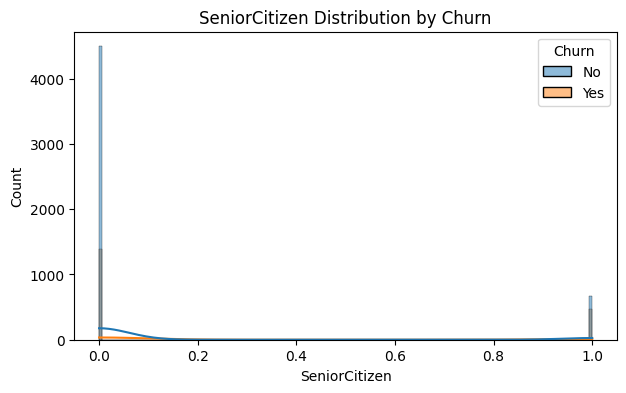

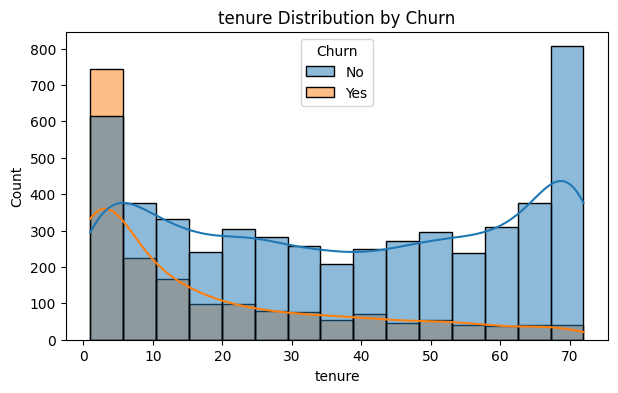

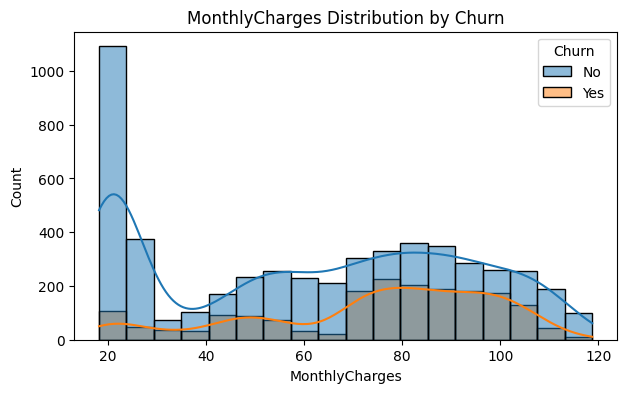

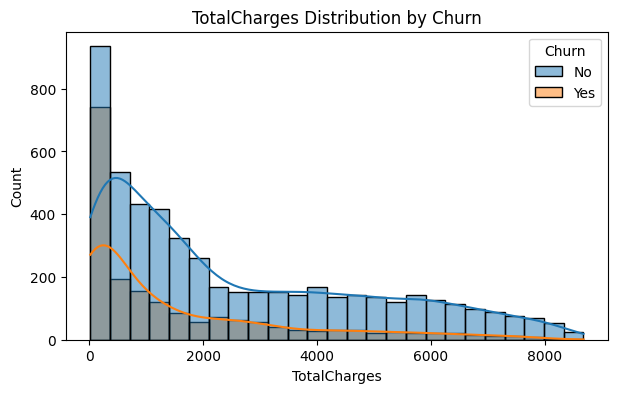

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
for col in num_fea:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, hue='Churn', kde=True)
    plt.title(f'{col} Distribution by Churn')
    plt.show()

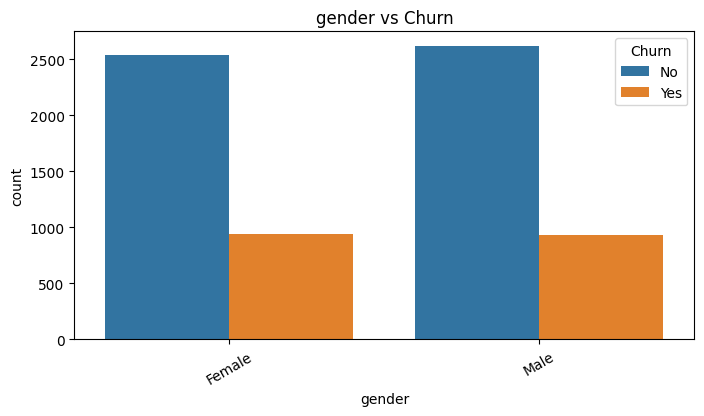

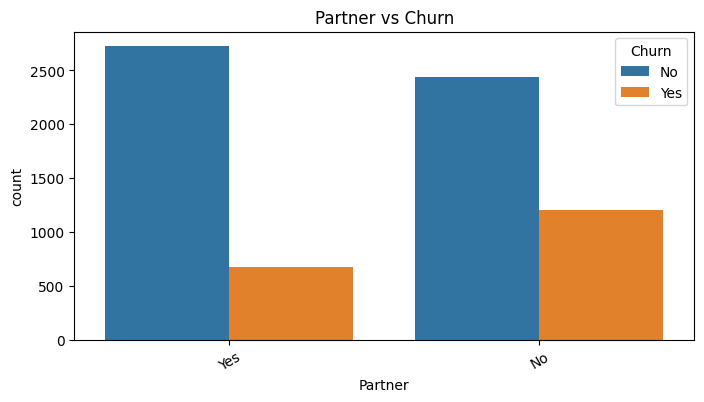

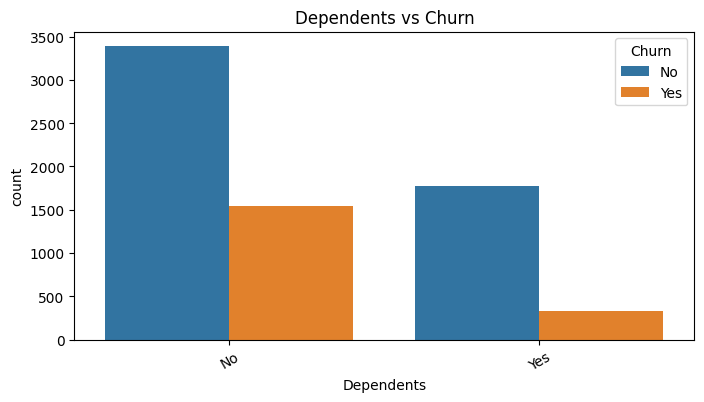

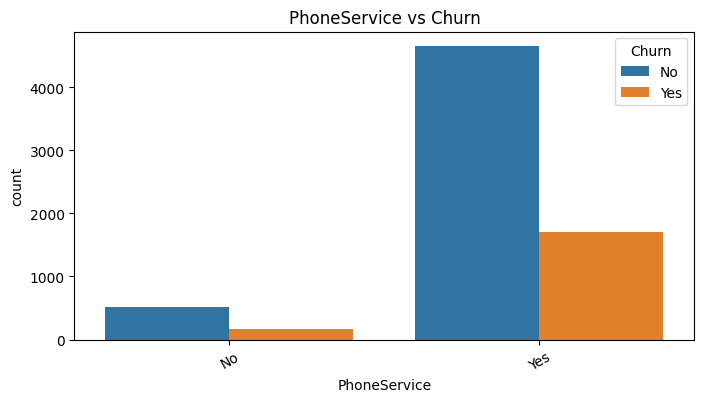

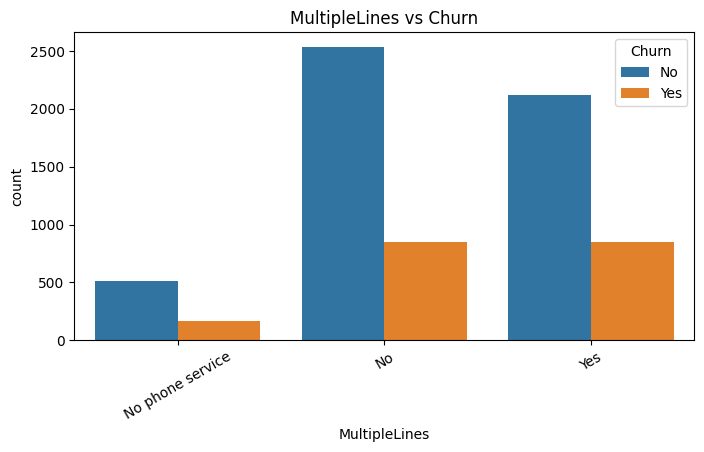

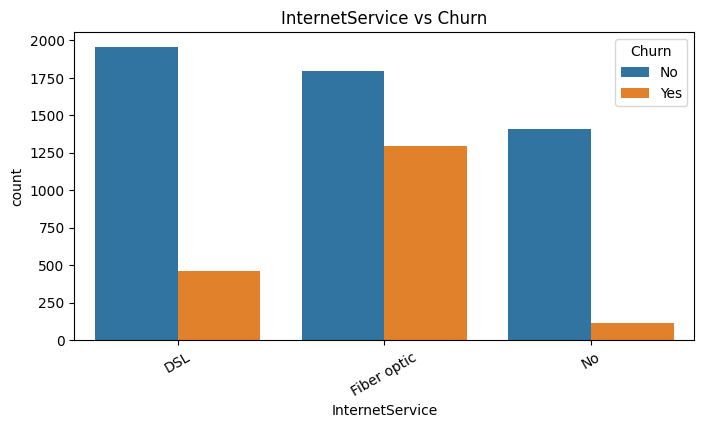

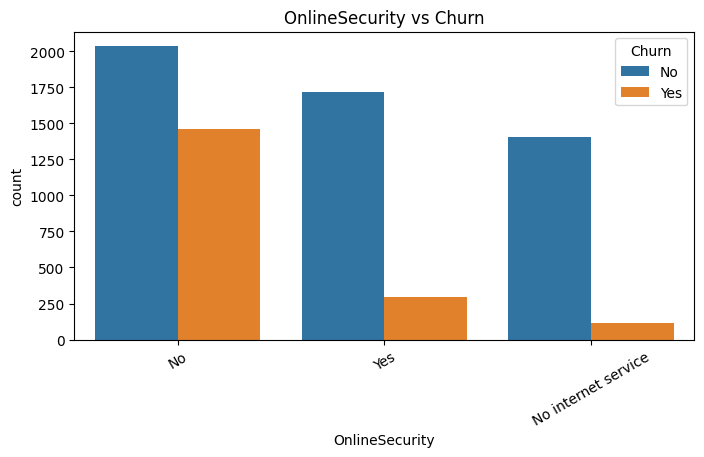

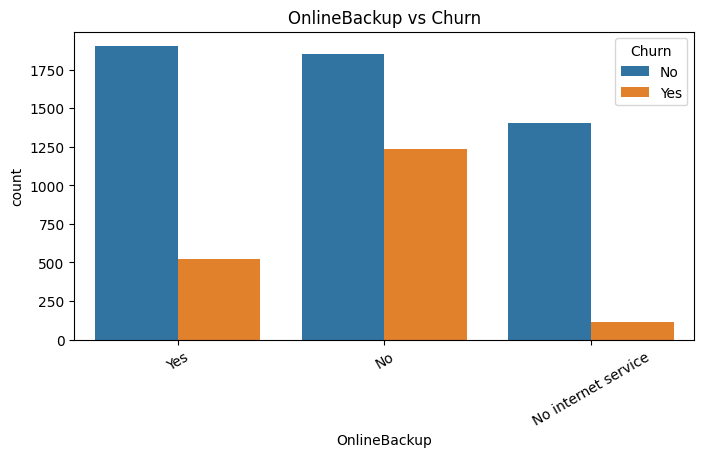

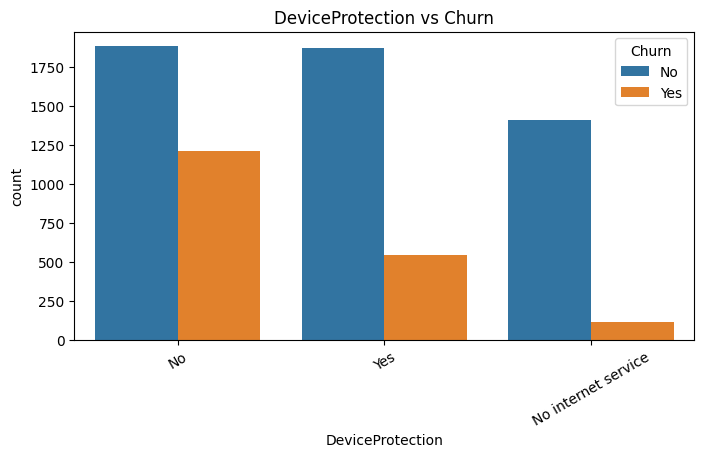

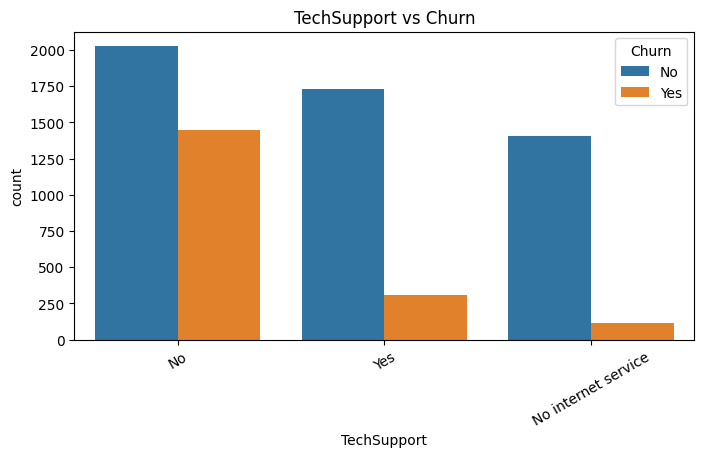

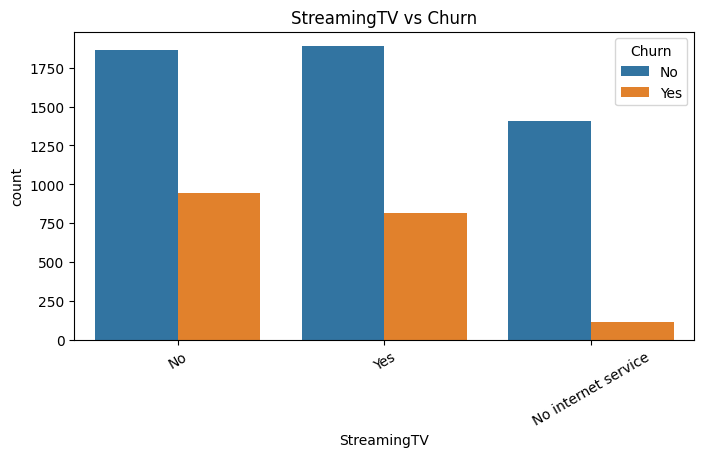

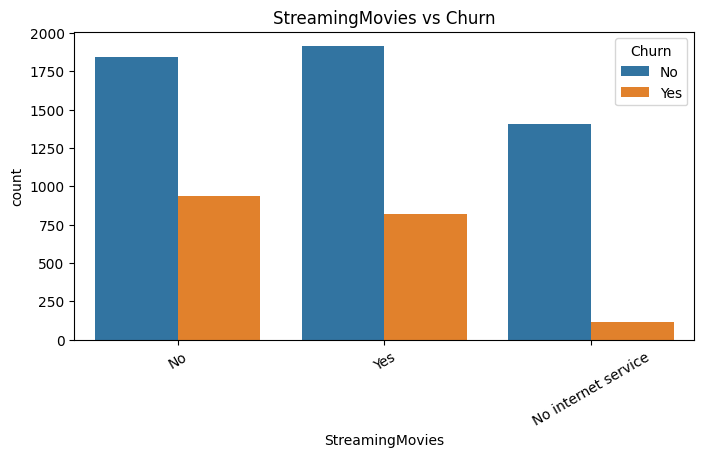

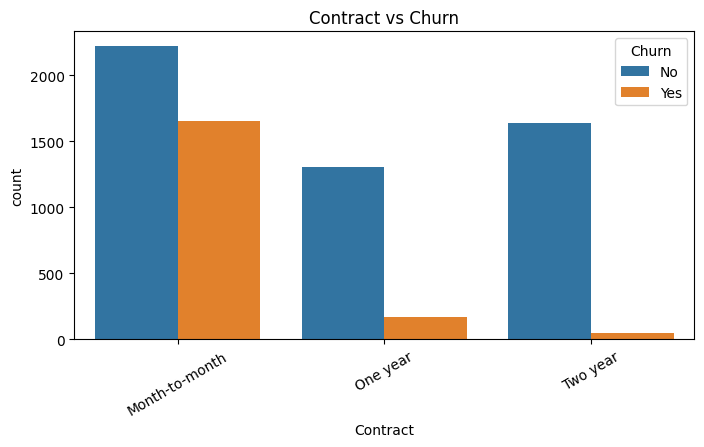

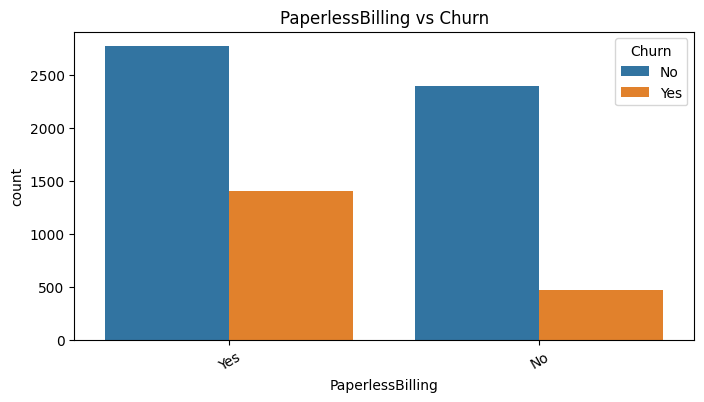

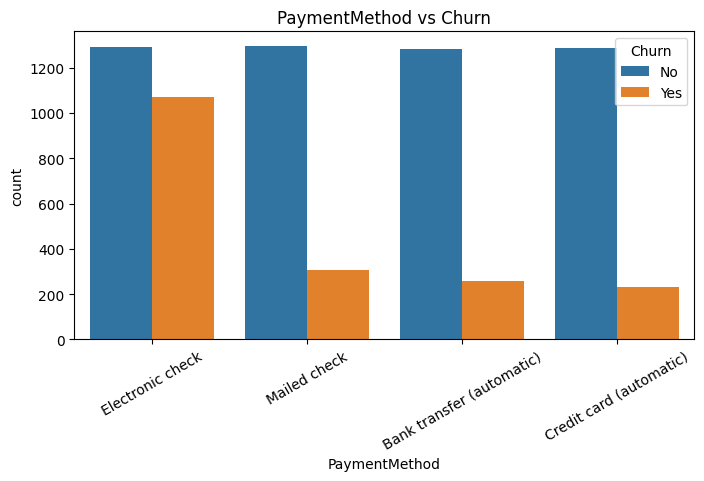

In [ ]:
for col in cat_fea:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue='Churn')
    plt.title(f'{col} vs Churn')
    plt.xticks(rotation=30)
    plt.show()

In [ ]:
df['Churn'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

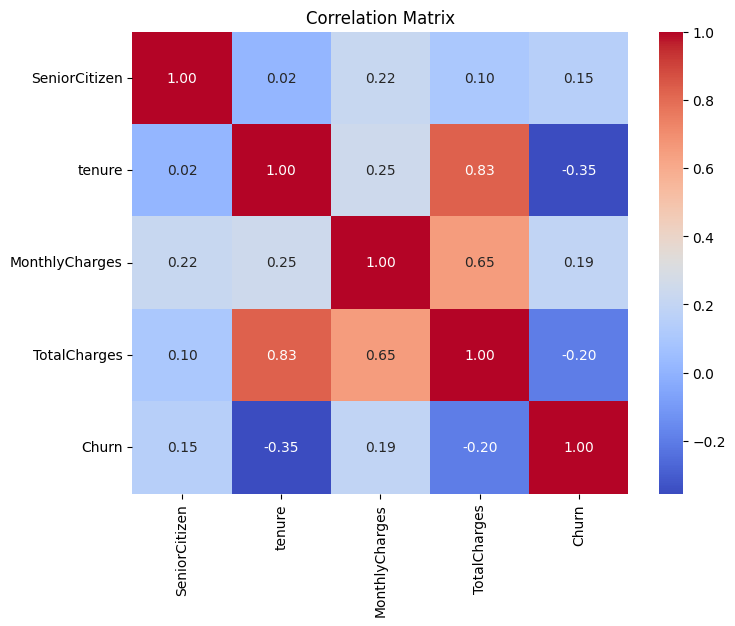

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [ ]:
X= df.drop(columns=["Churn"],axis=1)
y= df["Churn"]

In [ ]:
num_fea=X.select_dtypes(include=["int64","float64"]).columns
cat_fea=X.select_dtypes(include=["object"]).columns

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
#

In [ ]:
print(df.select_dtypes(include=["int64","float64"]).columns)
print(df.select_dtypes(include=["object"]).columns)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn'], dtype='object')
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [ ]:
num_pipe=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])
cat_pipe=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

In [ ]:
preprocessor=ColumnTransformer([
    ("num",num_pipe,num_fea),
    ("cat",cat_pipe,cat_fea)
])

In [ ]:
from sklearn.linear_model import LogisticRegression
lr_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LogisticRegression(max_iter=1000))
])
lr_model.fit(X_train,y_train)
y_pred=lr_model.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
y_pred = lr_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8038379530916845
Precision: 0.6484848484848484
Recall: 0.5721925133689839
F1: 0.6079545454545454

Confusion Matrix:
[[917 116]
 [160 214]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1:", f1_score(y_test, dt_pred))

Accuracy: 0.7306325515280739
Precision: 0.493368700265252
Recall: 0.49732620320855614
F1: 0.49533954727030627


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1:", f1_score(y_test, rf_pred))

Accuracy: 0.7896233120113717
Precision: 0.6344827586206897
Recall: 0.4919786096256685
F1: 0.5542168674698795


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred))
print("Recall:", recall_score(y_test, knn_pred))
print("F1:", f1_score(y_test, knn_pred))

Accuracy: 0.7604832977967306
Precision: 0.5468354430379747
Recall: 0.5775401069518716
F1: 0.5617685305591678


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['liblinear', 'lbfgs'],
    'model__class_weight': [None, 'balanced']
}
grid = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_

tuned_pred = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, tuned_pred))
print("Precision:", precision_score(y_test, tuned_pred))
print("Recall:", recall_score(y_test, tuned_pred))
print("F1:", f1_score(y_test, tuned_pred))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Accuracy: 0.7256574271499645
Precision: 0.4901315789473684
Recall: 0.7967914438502673
F1: 0.6069246435845214


In [ ]:
print(grid.best_params_)
print(grid.best_score_)

{'model__C': 1, 'model__class_weight': 'balanced', 'model__solver': 'liblinear'}
0.6335001521056969


In [ ]:
import numpy as np
y_prob = best_model.predict_proba(X_test)[:, 1]
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

    y_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_test, y_threshold))
    print("Recall:", recall_score(y_test, y_threshold))
    print("F1:", f1_score(y_test, y_threshold))


Threshold: 0.3
Precision: 0.41477949940405245
Recall: 0.93048128342246
F1: 0.5737840065952184

Threshold: 0.4
Precision: 0.4521497919556172
Recall: 0.8716577540106952
F1: 0.5954337899543379

Threshold: 0.5
Precision: 0.4901315789473684
Recall: 0.7967914438502673
F1: 0.6069246435845214

Threshold: 0.6
Precision: 0.5425101214574899
Recall: 0.7165775401069518
F1: 0.6175115207373272

Threshold: 0.7
Precision: 0.6111111111111112
Recall: 0.6176470588235294
F1: 0.6143617021276596


In [ ]:
feature_names = best_model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = best_model.named_steps[
    'model'
].coef_[0]

importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

importance['Abs_Coefficient'] = importance['Coefficient'].abs()

importance.sort_values(
    'Abs_Coefficient',
    ascending=False
).head(15)

,Feature,Coefficient,Abs_Coefficient
1,num__tenure,-1.250776,1.250776
38,cat__Contract_Two year,-0.785109,0.785109
36,cat__Contract_Month-to-month,0.692161,0.692161
16,cat__InternetService_Fiber optic,0.648090,0.648090
3,num__TotalCharges,0.607905,0.607905
2,num__MonthlyCharges,-0.606727,0.606727
15,cat__InternetService_DSL,-0.589545,0.589545
34,cat__StreamingMovies_No internet service,-0.259755,0.259755
25,cat__DeviceProtection_No internet service,-0.259755,0.259755
17,cat__InternetService_No,-0.259755,0.259755


Now I have finished my first classification model
Why I Chose Logistic Regression?

I selected Logistic Regression as my final model because it achieved the best overall performance among the baseline models I tested, with the highest accuracy (80.38%) and F1-score (60.80%).

Although Random Forest and Decision Tree were also tested, they did not achieve better overall results. Logistic Regression also provides interpretable coefficients, which help me understand how different features are associated with customer churn.

Therefore, I chose Logistic Regression because it offers a good balance between predictive performance and interpretability.